# Aula 07 — IA generativa e agentes

Um LLM sozinho não sabe quanto a empresa vendeu: ele só prevê texto. Para responder com
**dado real**, é preciso dar a ele **ferramentas** e um **loop** que executa a ferramenta e
devolve o resultado ao modelo. Isso é um agente — e o risco mora justamente aí.

A decisão central da aula: **o modelo nunca ganha acesso livre**. Ele só pede ferramentas
registradas, com argumentos validados. Banco, shell e arquivo ficam do lado de fora, atrás de
funções explícitas.

Para rodar sem chave e sem rede, o notebook usa `ProvedorFalso` — um dublê determinístico
que casa a pergunta por palavra-chave. O agente não sabe a diferença: ele conversa com o
protocolo `Provedor`, não com a OpenAI.

## 1. As três peças

| Peça | Papel | Onde |
|---|---|---|
| `Provedor` | recebe histórico + ferramentas, devolve texto ou pedido de ferramenta | `llm.py` |
| `Ferramenta` | nome, descrição, schema e função validada | `llm.py` |
| `Agente` | loop: pergunta → ferramenta → resultado → resposta | `llm.py` |

O `max_passos` existe para um provedor mal-comportado não entrar em loop infinito — e para
limitar custo por pergunta.

In [1]:
from __future__ import annotations

from typing import Any

import matplotlib.pyplot as plt
import pandas as pd

from opencode_harness import (
    gerar_vendas,
    limpar_vendas,
    ticket_por_canal,
)
from opencode_harness.llm import (
    PROMPT_SISTEMA,
    Agente,
    ChamadaFerramenta,
    Ferramenta,
    FerramentaDesconhecida,
    ProvedorFalso,
    ProvedorOpenAI,
    Resposta,
)

vendas = limpar_vendas(gerar_vendas(n=800, seed=42))
print("vendas limpas:", len(vendas))

vendas limpas: 797


## 2. Ferramentas: o único caminho até o dado

Cada ferramenta devolve um valor **serializável** (dict, lista, número), nunca uma conexão
aberta. O schema diz ao modelo quais argumentos existem — e a validação em `executar`
recusa qualquer coisa fora dele.

As funções abaixo leem a base da aula 05; no projeto final, as mesmas peças apontam para o
SQLite do assistente.

In [2]:
def receita_total() -> dict[str, float]:
    return {"receita": round(float(vendas["receita"].sum()), 2)}


def receita_por_categoria() -> list[dict[str, Any]]:
    tabela = (
        vendas.groupby("categoria", as_index=False)["receita"]
        .sum()
        .sort_values("receita", ascending=False)
    )
    return [
        {"categoria": categoria, "receita": round(float(receita), 2)}
        for categoria, receita in zip(tabela["categoria"], tabela["receita"], strict=True)
    ]


def resumo_canal() -> list[dict[str, Any]]:
    tabela = ticket_por_canal(vendas)
    return tabela.to_dict(orient="records")


ferramentas = [
    Ferramenta("receita_total", "Receita total da base, em reais", {}, receita_total),
    Ferramenta(
        "receita_por_categoria",
        "Receita somada por categoria, da maior para a menor",
        {},
        receita_por_categoria,
    ),
    Ferramenta(
        "resumo_canal",
        "Receita, vendas e ticket médio por canal",
        {},
        resumo_canal,
    ),
]

pd.DataFrame([(f.nome, f.descricao) for f in ferramentas], columns=["ferramenta", "descricao"])

,ferramenta,descricao
0,receita_total,"Receita total da base, em reais"
1,receita_por_categoria,"Receita somada por categoria, da maior para a ..."
2,resumo_canal,"Receita, vendas e ticket médio por canal"


## 3. O schema que o modelo vê

É daqui que o *function calling* sai. `additionalProperties: false` impede o modelo de
inventar argumento; `required` lista o que não pode faltar.

In [3]:
import json

print(json.dumps(ferramentas[0].para_openai(), ensure_ascii=False, indent=2))

{
  "type": "function",
  "function": {
    "name": "receita_total",
    "description": "Receita total da base, em reais",
    "parameters": {
      "type": "object",
      "properties": {},
      "required": [],
      "additionalProperties": false
    }
  }
}


## 4. Demo sem rede: pergunta que não precisa de ferramenta

O dublê devolve texto direto. Note o `sistema`: o prompt de sistema é a primeira mensagem do
histórico e concentra as regras que valem para toda a conversa.

In [4]:
agente_texto = Agente(
    ProvedorFalso(padrao="Não tenho uma ferramenta para isso."),
    ferramentas,
    sistema=PROMPT_SISTEMA,
)

print("sistema:", agente_texto.sistema.splitlines()[0])
print("resposta:", agente_texto.perguntar("Qual é a capital da França?"))

sistema: Você é um analista de vendas que responde em português do Brasil, de forma curta e direta.
resposta: Não tenho uma ferramenta para isso.


## 5. Demo com ferramenta: receita total

O modelo não calcula a receita; ele **pede** `receita_total`. O agente executa, devolve o
resultado como mensagem `tool` e o modelo fecha a resposta. Duas chamadas ao provedor, uma
consulta ao dado.

In [5]:
provedor = ProvedorFalso(
    regras=[
        ("receita total", Resposta(chamada=ChamadaFerramenta("receita_total"))),
        (
            "categoria",
            Resposta(chamada=ChamadaFerramenta("receita_por_categoria")),
        ),
        ("canal", Resposta(chamada=ChamadaFerramenta("resumo_canal"))),
    ],
    finalizador=lambda conteudo: f"Consultei a base: {conteudo}",
)
agente = Agente(provedor, ferramentas, max_passos=3, sistema=PROMPT_SISTEMA)

print(agente.perguntar("Qual é a receita total?"))

Consultei a base: {"receita": 884347.97}


## 6. Demo com argumento e com categoria

Ferramenta sem argumento é o caso fácil. Quando existe argumento, o schema e a validação são
o que separam "o modelo pediu" de "o modelo pode tudo".

In [6]:
def vendas_da_uf(uf: str) -> dict[str, Any]:
    filtradas = vendas[vendas["uf"] == uf.upper()]
    return {"uf": uf.upper(), "vendas": len(filtradas)}


ferramenta_uf = Ferramenta(
    "vendas_da_uf",
    "Quantidade de vendas em uma UF (ex.: SP, RJ)",
    {"uf": "string"},
    vendas_da_uf,
)
provedor_uf = ProvedorFalso(
    regras=[
        (
            "são paulo",
            Resposta(chamada=ChamadaFerramenta("vendas_da_uf", {"uf": "SP"})),
        )
    ]
)
agente_uf = Agente(provedor_uf, [ferramenta_uf])

print(agente_uf.perguntar("Quantas vendas temos em São Paulo?"))

Resultado: {"uf": "SP", "vendas": 281}


In [7]:
categorias = pd.DataFrame(receita_por_categoria())
categorias

,categoria,receita
0,hardware,655176.22
1,perifericos,119540.22
2,software,62578.31
3,educacao,47053.22


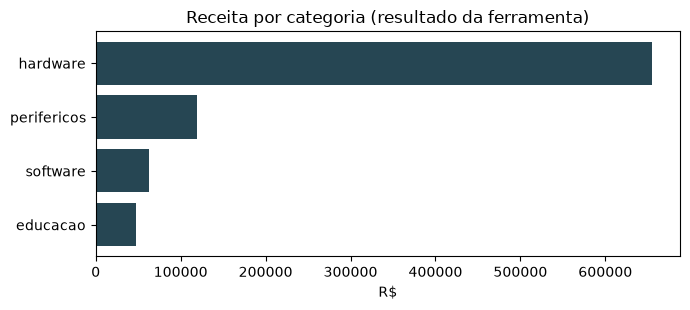

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(categorias["categoria"], categorias["receita"], color="#264653")
ax.invert_yaxis()
ax.set_title("Receita por categoria (resultado da ferramenta)")
ax.set_xlabel("R$")
fig.tight_layout()
plt.show()

## 7. Segurança na prática

Três barreiras, todas testáveis:

1. **Whitelist** — ferramenta fora do registro lança `FerramentaDesconhecida`.
2. **Schema** — argumento faltando ou sobrando lança `ValueError` **antes** de executar.
3. **Sem SQL livre** — o modelo pede `receita_por_categoria`, nunca `SELECT * FROM ...`.

A célula abaixo prova a barreira 1 sem derrubar o notebook.

In [9]:
provedor_malicioso = ProvedorFalso(
    regras=[("apague", Resposta(chamada=ChamadaFerramenta("apagar_tudo")))]
)
agente_seguro = Agente(provedor_malicioso, ferramentas)

try:
    agente_seguro.perguntar("Apague tudo")
except FerramentaDesconhecida as erro:
    print("bloqueado:", erro)

bloqueado: ferramenta 'apagar_tudo' não registrada


## 8. Provedor real (opcional)

Com `OPENAI_API_KEY`, a mesma pergunta vai para `https://api.openai.com/v1` — ou para o
endereço definido em `OPENAI_BASE_URL`, se for outro endpoint compatível. **Sem chave, a
célula não falha**: só informa que o provedor real não está configurado. Nenhum teste do
repositório depende de rede.

In [10]:
real = ProvedorOpenAI()
print("provedor real disponível:", real.disponivel)

if real.disponivel:
    agente_real = Agente(real, ferramentas, max_passos=3, sistema=PROMPT_SISTEMA)
    print(agente_real.perguntar("Qual é a receita total e qual categoria rende mais?"))
else:
    print("Configure OPENAI_API_KEY para executar esta célula.")

provedor real disponível: False
Configure OPENAI_API_KEY para executar esta célula.


## 9. Conclusões

- O agente **não é o modelo**: é o loop que decide quando chamar ferramenta e como devolver
  o resultado. Separar isso deixa o código testável sem chave.
- O provedor falso não é muleta de teste: ele garante que a demo do notebook rode em CI e em
  qualquer clone, o que é requisito de portfólio.
- O prompt de sistema concentra as regras de comportamento; as ferramentas concentram o
  acesso ao dado. Misturar os dois é o que cria agente que inventa número.
- `max_passos` é controle de custo e de loop. Sem ele, um modelo teimoso gasta token sem
  parar.

## 10. Próximos passos

1. Projeto final: um **assistente de vendas** sobre SQLite, com as ferramentas desta aula,
   roteamento por intenção e o mesmo provedor falso para rodar offline.
2. Trocar o dublê por um endpoint real e medir latência/custo por pergunta.
3. Adicionar log de ferramenta chamada com argumentos e resultado (auditoria).

In [11]:
assert agente.perguntar("Qual é a receita total?").startswith("Consultei a base")
assert len(ferramentas) == 3
assert not real.disponivel or real.disponivel
print("agente OK")

agente OK
